Entropy of PlayTennis: 0.9403
Information gain(Outlook) = 0.2467
Information gain(Temperature) = 0.0292
Information gain(Humidity) = 0.1518
Information gain(Wind) = 0.0481

New sample: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
Predicted PlayTennis = No


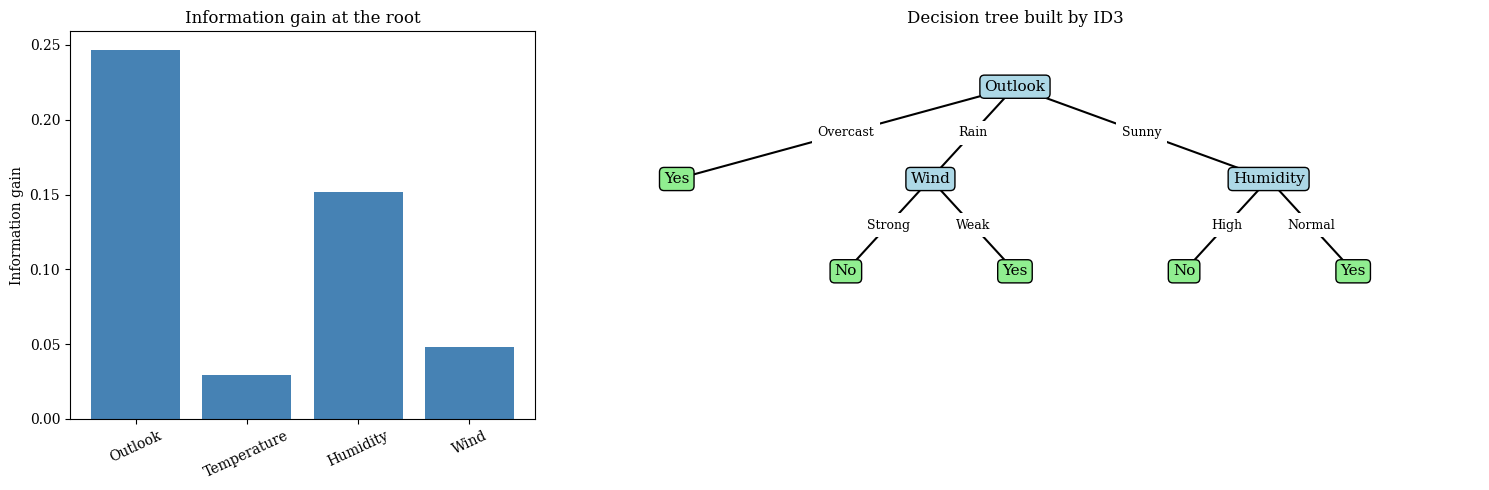

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "serif"

data = pd.DataFrame({
 "Outlook":["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast","Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
 "Temperature":["Hot","Hot","Hot","Mild","Cool","Cool","Cool","Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
 "Humidity":["High","High","High","High","Normal","Normal","Normal","High","Normal","Normal","Normal","High","Normal","High"],
 "Wind":["Weak","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
 "PlayTennis":["No","No","Yes","Yes","Yes","No","Yes","No","Yes","Yes","Yes","Yes","Yes","No"]})
target = "PlayTennis"

def entropy(col):
    p = col.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def info_gain(d, attr):
    total = entropy(d[target])
    weighted = sum(len(s) / len(d) * entropy(s[target]) for _, s in d.groupby(attr))
    return total - weighted

def id3(d, attrs):
    if d[target].nunique() == 1:
        return d[target].iloc[0]
    if not attrs:
        return d[target].mode()[0]
    best = max(attrs, key=lambda a: info_gain(d, a))
    node = {"attr": best, "children": {}}
    for v, subset in d.groupby(best):
        node["children"][v] = id3(subset, [a for a in attrs if a != best])
    return node

features = [c for c in data.columns if c != target]
print("Entropy of PlayTennis:", round(entropy(data[target]), 4))
gains = {a: info_gain(data, a) for a in features}
for a, g in gains.items():
    print(f"Information gain({a}) = {g:.4f}")

tree = id3(data, features)

def classify(t, sample):
    while isinstance(t, dict):
        t = t["children"][sample[t["attr"]]]
    return t

new_sample = {"Outlook": "Sunny", "Temperature": "Cool", "Humidity": "High", "Wind": "Strong"}
print("\nNew sample:", new_sample)
print("Predicted PlayTennis =", classify(tree, new_sample))

# ---- Graph: information gain + the tree
def leaves(t):
    return 1 if not isinstance(t, dict) else sum(leaves(c) for c in t["children"].values())

def draw(t, ax, x, y, width, parent=None, edge=""):
    leaf = not isinstance(t, dict)
    ax.text(x, y, t if leaf else t["attr"], ha="center", va="center", fontsize=11, zorder=3,
            bbox=dict(boxstyle="round", fc="lightgreen" if leaf else "lightblue", ec="black"))
    if parent:
        ax.plot([parent[0], x], [parent[1], y], "k-", zorder=1)
        ax.text((parent[0]+x)/2, (parent[1]+y)/2, edge, fontsize=9, ha="center", va="center",
                bbox=dict(fc="white", ec="none"), zorder=2)
    if not leaf:
        total, left = leaves(t), x - width / 2
        for v, c in t["children"].items():
            w = width * leaves(c) / total
            draw(c, ax, left + w / 2, y - 1, w, (x, y), v)
            left += w

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(gains.keys(), gains.values(), color="steelblue")
ax[0].set_ylabel("Information gain"); ax[0].set_title("Information gain at the root")
ax[0].tick_params(axis="x", rotation=25)
draw(tree, ax[1], 0, 0, 10)
ax[1].set_xlim(-5.5, 5.5); ax[1].set_ylim(-3.6, 0.6); ax[1].axis("off")
ax[1].set_title("Decision tree built by ID3")
plt.tight_layout(); plt.show()